In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from src.features.extract import feature_groups, morphological_features

sns.set_theme(style="whitegrid")
FCFG = yaml.safe_load((PROJECT_ROOT / "configs" / "features.yaml").read_text(encoding="utf-8"))
PCFG = yaml.safe_load((PROJECT_ROOT / "configs" / "preprocessing.yaml").read_text(encoding="utf-8"))
FIG_DIR = PROJECT_ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = PCFG["classes"]; FS = FCFG["fs"]; SEED = PCFG["seed"]

df = pd.read_csv(PROJECT_ROOT / FCFG["output"]["features"], dtype={"record_id": str})
META = ["record_id", "sample", "symbol", "label", "split"]
FEATS = [c for c in df.columns if c not in META]
GROUPS = feature_groups(FEATS)
print(df.shape, "|", {g: len(c) for g, c in GROUPS.items()})
tr = df[df.split == "train"]            # TOUTE sélection/analyse ci-dessous : train seulement
print("Train :", tr.shape)

(100690, 41) | {'morph': 9, 'stat': 9, 'freq': 13, 'rr': 5}
Train : (40049, 41)


In [2]:
nan = df[FEATS].isna().sum()
print(nan[nan > 0])
print("Records concernés :", df[df.rr_prev.isna() | df.rr_local.isna()].record_id.nunique())

rr_prev                31
rr_next                29
rr_local               75
rr_ratio_prev_local    75
rr_ratio_next_prev     60
dtype: int64
Records concernés : 44


In [3]:
key = ["m_qrs_width_ms", "m_r_amp", "m_qrs_area", "m_max_slope", "s_kurtosis",
       "f_centroid", "f_rbp_0p5_5", "rr_prev", "rr_ratio_prev_local", "rr_ratio_next_prev"]
tab = tr.groupby("label")[key].median().rename(index=dict(enumerate(CLASSES))).round(3)
print(tab.T)

label                      N        S        V        F
m_qrs_width_ms        61.111   52.778  116.667   50.000
m_r_amp                9.233   10.149    8.474   11.944
m_qrs_area             0.337    0.313    0.611    0.504
m_max_slope          782.923  989.750  440.989  702.640
s_kurtosis             7.591   10.477    0.617    7.338
f_centroid            10.345   14.155    3.969    6.650
f_rbp_0p5_5            0.180    0.082    0.625    0.416
rr_prev                0.747    0.475    0.514    0.583
rr_ratio_prev_local    1.003    0.776    0.702    0.946
rr_ratio_next_prev     0.992    1.299    1.713    0.791


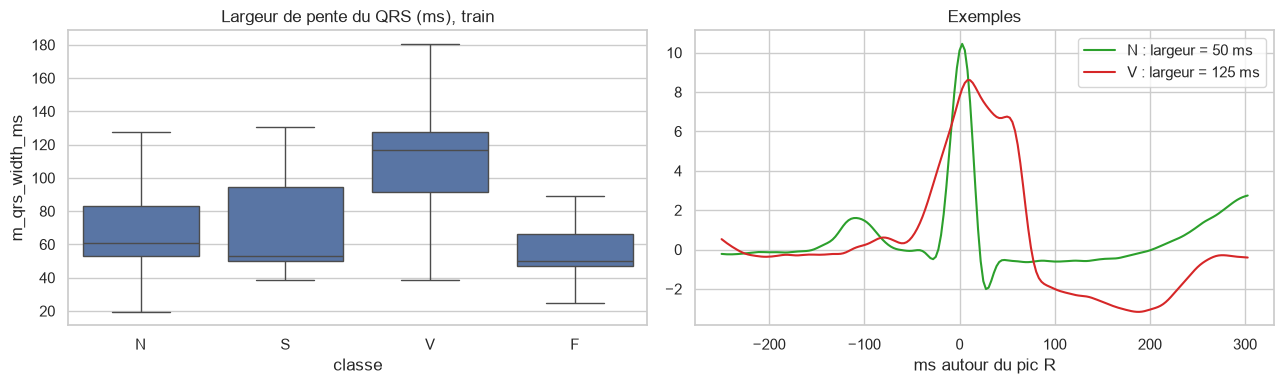

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sample = tr.sample(n=min(20000, len(tr)), random_state=SEED).copy()
sample["classe"] = sample.label.map(dict(enumerate(CLASSES)))
sns.boxplot(data=sample, x="classe", y="m_qrs_width_ms", order=CLASSES, ax=axes[0], showfliers=False)
axes[0].set_title("Largeur de pente du QRS (ms), train")

d = np.load(PROJECT_ROOT / PCFG["output"]["dataset"])
rng = np.random.default_rng(SEED)
t = np.arange(-PCFG["window"]["pre"], PCFG["window"]["post"]) / FS * 1000
for cls_id, col in [(0, "tab:green"), (2, "tab:red")]:
    idx = np.where((d["split"] == "train") & (d["y"] == cls_id))[0]
    j = rng.choice(idx)
    w = morphological_features(d["X"][j:j + 1], FCFG["pre"], FS)["m_qrs_width_ms"].iloc[0]
    axes[1].plot(t, d["X"][j], color=col, label=f"{CLASSES[cls_id]} : largeur = {w:.0f} ms")
axes[1].legend(); axes[1].set_xlabel("ms autour du pic R"); axes[1].set_title("Exemples")
plt.tight_layout(); fig.savefig(FIG_DIR / "feature_qrs_width.png", dpi=150)

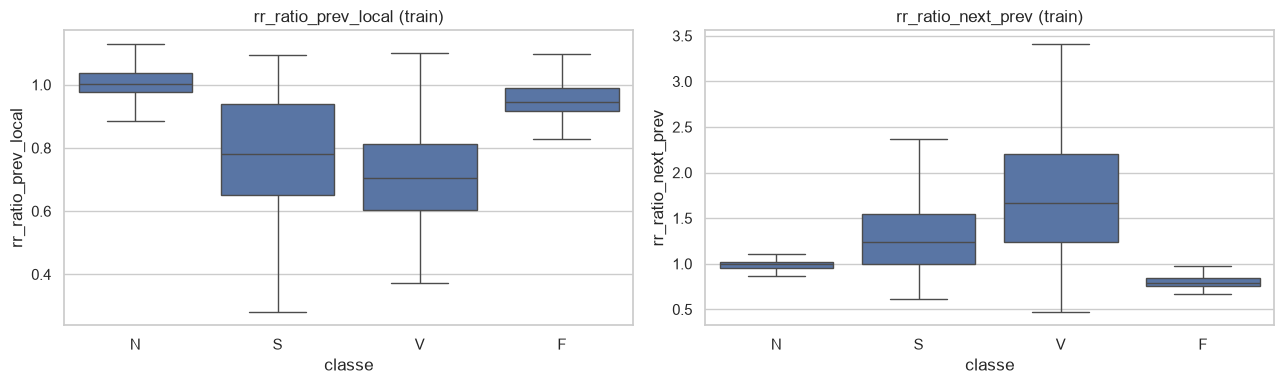

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["rr_ratio_prev_local", "rr_ratio_next_prev"]):
    sns.boxplot(data=sample, x="classe", y=col, order=CLASSES, ax=ax, showfliers=False)
    ax.set_title(col + " (train)")
plt.tight_layout(); fig.savefig(FIG_DIR / "feature_rr.png", dpi=150)

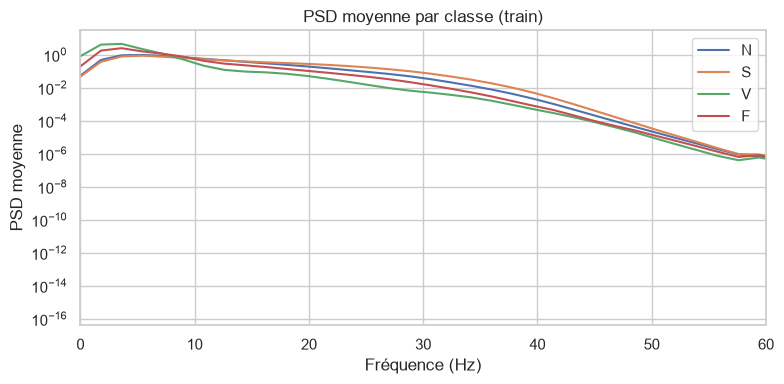

In [6]:
from scipy import signal as sps
f, P = sps.periodogram(d["X"][d["split"] == "train"].astype(np.float64), fs=FS,
                       window="hann", detrend="constant", axis=1)
y_tr = d["y"][d["split"] == "train"]
plt.figure(figsize=(8, 4))
for i, c in enumerate(CLASSES):
    plt.semilogy(f, P[y_tr == i].mean(axis=0), label=c)
plt.xlim(0, 60); plt.xlabel("Fréquence (Hz)"); plt.ylabel("PSD moyenne"); plt.legend()
plt.title("PSD moyenne par classe (train)"); plt.tight_layout()
plt.savefig(FIG_DIR / "feature_psd_per_class.png", dpi=150)

In [7]:
from sklearn.feature_selection import f_classif, mutual_info_classif

Xtr = tr[FEATS].copy()
Xtr = Xtr.fillna(Xtr.median())                       # médiane du TRAIN
F, _ = f_classif(Xtr, tr.label)
sub = Xtr.sample(n=min(20000, len(Xtr)), random_state=SEED)
mi = mutual_info_classif(sub, tr.loc[sub.index, "label"], random_state=SEED)
rank = pd.DataFrame({"F_anova": F, "info_mutuelle": mi}, index=FEATS)
print(rank.sort_values("info_mutuelle", ascending=False).head(15).round(3))

                      F_anova  info_mutuelle
rr_ratio_prev_local  4585.316          0.197
m_post_peak           456.867          0.194
f_rbp_0p5_5          8577.687          0.184
s_kurtosis           2500.146          0.182
f_centroid           3546.236          0.182
rr_ratio_next_prev   9683.321          0.180
f_rbp_1015           6185.572          0.177
f_entropy            5236.435          0.176
rr_prev              2241.113          0.151
f_bp_0p5_5           9004.716          0.143
f_rbp_1525           1638.423          0.134
m_qrs_neg             203.074          0.123
m_qrs_width_ms       2714.132          0.109
f_rbp_2540           1408.616          0.109
rr_next               671.590          0.096


6 paires avec |r| > 0.95 :
('m_qrs_pos', 's_max', np.float64(0.987))
('m_qrs_area', 's_std', np.float64(0.955))
('s_std', 's_var', np.float64(0.958))
('s_std', 's_energy', np.float64(0.953))
('s_var', 's_energy', np.float64(0.991))
('f_rbp_1525', 'f_centroid', np.float64(0.965))


[None, None, None, None, None, None]

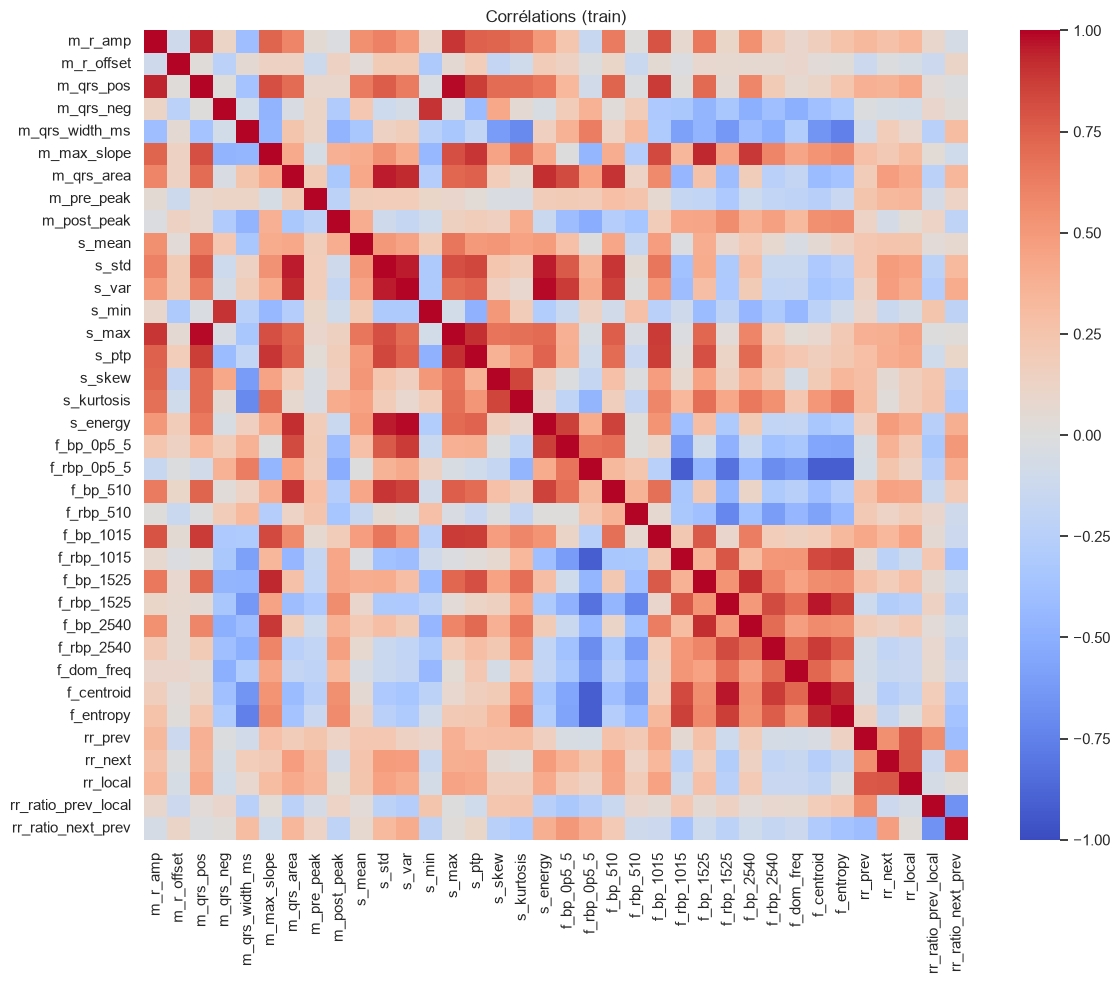

In [8]:
corr = Xtr.corr()
plt.figure(figsize=(12, 10)); sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélations (train)"); plt.tight_layout()
plt.savefig(FIG_DIR / "feature_corr.png", dpi=150)
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(FEATS)
         for b in FEATS[i + 1:] if abs(corr.loc[a, b]) > 0.95]
print(len(pairs), "paires avec |r| > 0.95 :"); [print(p) for p in pairs]

In [9]:
for g, cols in GROUPS.items():
    print(f"{g:6s} ({len(cols):2d}) :", cols)
print("\nSans le rythme :", sum(len(c) for g, c in GROUPS.items() if g != "rr"), "features")

morph  ( 9) : ['m_r_amp', 'm_r_offset', 'm_qrs_pos', 'm_qrs_neg', 'm_qrs_width_ms', 'm_max_slope', 'm_qrs_area', 'm_pre_peak', 'm_post_peak']
stat   ( 9) : ['s_mean', 's_std', 's_var', 's_min', 's_max', 's_ptp', 's_skew', 's_kurtosis', 's_energy']
freq   (13) : ['f_bp_0p5_5', 'f_rbp_0p5_5', 'f_bp_510', 'f_rbp_510', 'f_bp_1015', 'f_rbp_1015', 'f_bp_1525', 'f_rbp_1525', 'f_bp_2540', 'f_rbp_2540', 'f_dom_freq', 'f_centroid', 'f_entropy']
rr     ( 5) : ['rr_prev', 'rr_next', 'rr_local', 'rr_ratio_prev_local', 'rr_ratio_next_prev']

Sans le rythme : 31 features
